# 02 - Patient folds, image audit and duplicate removal

1. Create three stratified patient folds. Each patient validates once and trains twice.
2. Audit every JPEG for unreadable images and duplicates.
3. Remove duplicate images and save the image table.

**Needs:** `data/train_labels.csv`, `data/train/*.jpg`
**Writes:** `results/splits_fold_1.csv` through `splits_fold_3.csv`, plus the audit and cleaned image table.
`results/splits.csv` and the cleaned table's `split` column retain fold 1 for existing single-run notebooks.
Run `04_image_cross_validation.ipynb` to train and validate all three folds.


In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# Find the project root (the folder holding pyproject.toml) and make src/ importable.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from melanoma_detection.utils import RANDOM_STATE, get_project_paths, setup_logging
from melanoma_detection import data, splitting
setup_logging()
P = get_project_paths(ROOT)   # edit get_project_paths(ROOT, data_dir=...) if your data lives elsewhere
print("Project root:", P.root)

Project root: C:\Users\jjk91\OneDrive\Documents\GitHub\ADS2002-Melanoma


## 1 - Three stratified patient folds

Each run uses approximately 67% of patients for training and 33% for validation.
Stratification uses whether a patient has any malignant image.


In [2]:
clean = data.clean_train_labels(data.load_labels(P.labels))
patients = data.build_patient_table(clean)

split_maps = splitting.patient_level_split(patients, seed=RANDOM_STATE, n_splits=3)
for fold, fold_images in splitting.iter_patient_folds(clean, split_maps):
    splitting.save_splits(split_maps[fold - 1], P.results / f"splits_fold_{fold}.csv")
    print(f"Fold {fold}")
    display(splitting.summarise_splits(fold_images).round(1))

# Keep fold 1 as the default for the existing single-run notebooks.
clean = splitting.assign_splits(clean, split_maps[0])
splitting.save_splits(split_maps[0], P.splits)


Fold 1


,patients,images,melanoma,non_melanoma,melanoma_percent
split,,,,,
train,281,4674,87,4587,1.9
validation,141,2190,41,2149,1.9


Fold 2


,patients,images,melanoma,non_melanoma,melanoma_percent
split,,,,,
train,281,4588,84,4504,1.8
validation,141,2276,44,2232,1.9


Fold 3


,patients,images,melanoma,non_melanoma,melanoma_percent
split,,,,,
train,282,4466,85,4381,1.9
validation,140,2398,43,2355,1.8


WindowsPath('C:/Users/jjk91/OneDrive/Documents/GitHub/ADS2002-Melanoma/results/splits.csv')

## 2 · Audit the image folder

The audit hashes every image, so the first run is slow. The result is cached in `results/image_audit.pkl`; **delete that file if the images in `train/` change**.

In [3]:
image_audit = data.audit_images(P.images, cache_path=P.image_audit)
image_audit = data.attach_metadata(image_audit, clean)

counts, tables = data.summarise_audit(image_audit, clean)
display(counts.to_frame())

Audited 250/6,864 files
Audited 500/6,864 files
Audited 750/6,864 files
Audited 1,000/6,864 files
Audited 1,250/6,864 files
Audited 1,500/6,864 files
Audited 1,750/6,864 files
Audited 2,000/6,864 files
Audited 2,250/6,864 files
Audited 2,500/6,864 files
Audited 2,750/6,864 files
Audited 3,000/6,864 files
Audited 3,250/6,864 files
Audited 3,500/6,864 files
Audited 3,750/6,864 files
Audited 4,000/6,864 files
Audited 4,250/6,864 files
Audited 4,500/6,864 files
Audited 4,750/6,864 files
Audited 5,000/6,864 files
Audited 5,250/6,864 files
Audited 5,500/6,864 files
Audited 5,750/6,864 files
Audited 6,000/6,864 files
Audited 6,250/6,864 files
Audited 6,500/6,864 files
Audited 6,750/6,864 files
Audited 6,864/6,864 files


,Count
Metadata images,6864
Files checked,6864
Readable images,6864
Missing metadata images,0
Metadata IDs matching multiple entries,0
Files without metadata,0
Unreadable or non-image entries,0
Readable images that are not JPEG,0
Readable images with mode other than RGB,0
Images with decoder warnings,0


In [4]:
# Inspect any table that has rows (empty tables are skipped).
for title, table in tables.items():
    if not table.empty:
        print(f"\n{title}: {len(table)} row(s), showing up to 10")
        display(table.head(10))


Exact pixel duplicates: 158 row(s), showing up to 10


,pixel_hash,files,images,patients,split_count,label_count,pixel_versions
0,02d438f4fdaac419d2ddc27963b1a2eeeafba5662ecdd8...,2,"ISIC_1594422, ISIC_2449313",1,1,1,1
1,038bfe519dcb9248e7a4ee5914c92823e5dcb1427cf880...,2,"ISIC_1664534, ISIC_4176335",1,1,1,1
2,04dc39a7d194698ad331916d34bd73fe9d6f6f97a9a650...,2,"ISIC_3289574, ISIC_3358528",1,1,1,1
3,06c42201cda30333b067192c92c9ac6ee9ba27476cec22...,2,"ISIC_0363130, ISIC_2750577",1,1,1,1
4,09298de440420ec7e1112bf90b8a14292a15aaa271561f...,2,"ISIC_8876993, ISIC_9053755",1,1,1,1
5,0b5990b9602be5bfba5767da5f186a21e90d4dafebf4bd...,2,"ISIC_1388984, ISIC_7343798",1,1,1,1
6,0b5c6f766df5224b70a3f9d88ea8be33b1a536af415243...,2,"ISIC_7365445, ISIC_7791770",1,1,1,1
7,0e10afa5ab7cf0dd48905803f5f31fa1e1261acc86bde5...,2,"ISIC_0481910, ISIC_5889146",1,1,1,1
8,0f6ec9fce59f53660bf8253b10aab29eb9d8d31d028986...,2,"ISIC_3927991, ISIC_9104012",1,1,1,1
9,0fc468d4b6492622d0a5ac508c31a4b99fe0d9d862d339...,2,"ISIC_8889856, ISIC_9677697",1,1,1,1



Identical file duplicates: 158 row(s), showing up to 10


,file_hash,files,images,patients,split_count,label_count,pixel_versions
0,014d7b66674929fb59a573221de7a2431d2bce73fc76bd...,2,"ISIC_0401116, ISIC_0467724",1,1,1,1
1,04d46ee3f9cf89cece1d419044ddfeabbf50e56c0c01da...,2,"ISIC_0956562, ISIC_4528262",1,1,1,1
2,053d4e00e0dca57b679b8b58891ba581f7f0c7dccb6113...,2,"ISIC_5644962, ISIC_8667588",1,1,1,1
3,05df5f12e088a8455c0f90b9e5d3afd2231c60cccdb019...,2,"ISIC_0721819, ISIC_8317513",1,1,1,1
4,0781641ec5c258ae54af0ec2cec2cc9372f4a6a37a1886...,2,"ISIC_2636012, ISIC_9917477",1,1,1,1
5,0bf673d49d25e9d403d9cdbbe60d37ea1fc7ef98e2570f...,2,"ISIC_1309015, ISIC_8170849",1,1,1,1
6,12fcef8d2398525467df3ca69c329a148883d15275b389...,2,"ISIC_1621479, ISIC_7472836",1,1,1,1
7,14125eab3fb2a9283ce9670de9c550f84dc83119c394a3...,2,"ISIC_1388230, ISIC_7713545",1,1,1,1
8,176b31649425769c880c7a4c11583a6c7aaf7d3e722333...,2,"ISIC_1312208, ISIC_2749059",1,1,1,1
9,17f5ddc6deda8ba83cd49d7a7fd4192d653100dc156d84...,2,"ISIC_3218501, ISIC_7718526",1,1,1,1



Similarity candidates (NOT confirmed duplicates): 6 row(s), showing up to 10


,dhash,files,images,patients,split_count,label_count,pixel_versions
0,00448e9d8fcdf9af,2,"ISIC_2887033, ISIC_5194874",1,1,1,2
85,e0f0f0ccccccf0f0,2,"ISIC_3722850, ISIC_4539674",2,1,1,2
129,f0f0cccc8cccf0f0,2,"ISIC_4646061, ISIC_5565053",2,1,1,2
130,f0f0ccccccccf0f0,2,"ISIC_2798803, ISIC_6799627",2,2,1,2
134,f0f0f0ccccf0f0d8,2,"ISIC_0364641, ISIC_0709041",2,2,1,2
135,f0f0f0ececf0f0f0,2,"ISIC_0228713, ISIC_9070899",1,1,1,2


## 3 · Review near-duplicates by eye

Exact duplicates are removed automatically. Near-duplicates (similar but not pixel-identical) need a human decision.

List the pairs you **visually confirmed** below as `(image_to_keep, image_to_drop)`. The pair from the original notebook is pre-filled; re-check it in the plot.

,image_name,patient_id,sex,age_approx,anatom_site_general_challenge,diagnosis,benign_malignant,target,site_missing,split
1907,ISIC_2887033,IP_3673974,female,50,upper extremity,unknown,benign,0,0,train
3511,ISIC_5194874,IP_3673974,female,50,upper extremity,unknown,benign,0,0,train


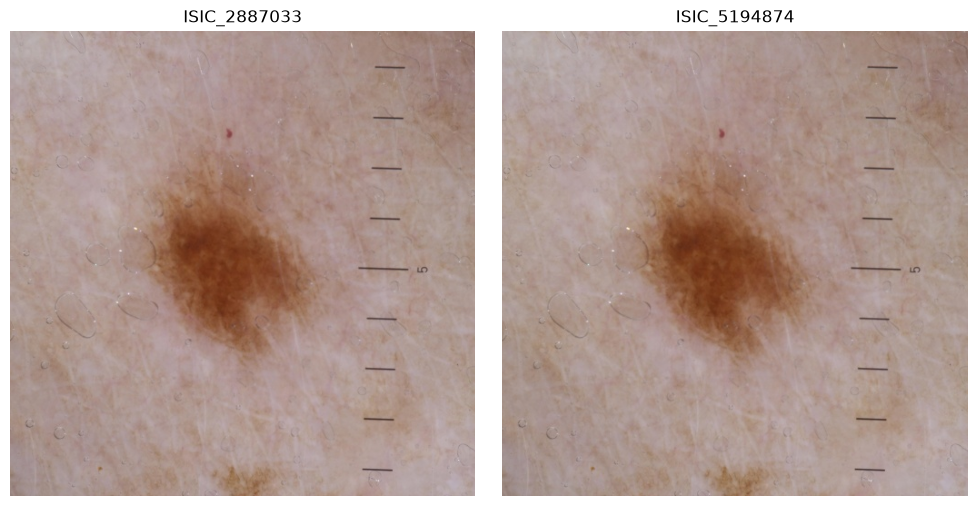

In [5]:
CONFIRMED_PAIRS = [("ISIC_2887033", "ISIC_5194874")]

from PIL import Image

for kept, dropped in CONFIRMED_PAIRS:
    display(clean.loc[clean["image_name"].isin([kept, dropped])])
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    for ax, image_id in zip(axes, [kept, dropped]):
        file_path = image_audit.loc[image_audit["image_name"].eq(image_id), "file_path"].iloc[0]
        ax.imshow(Image.open(file_path).convert("RGB"))
        ax.set_title(image_id)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 4 · Remove duplicates

Within each duplicate group the lowest image ID is kept. This **raises** if two duplicates disagree on patient, split, label, sex, age or site, which would mean something is wrong.

In [6]:
clean_images, removal_log = data.remove_duplicates(clean, image_audit, CONFIRMED_PAIRS)

print(f"Kept {len(clean_images):,} images, removed {len(removal_log):,}")
display(removal_log)

Kept 6,705 images, removed 159


,excluded_image,retained_image,patient_id,split,target,file_path,reason
0,ISIC_0378118,ISIC_0316025,IP_4488328,train,0,C:\Users\jjk91\OneDrive\Documents\GitHub\ADS20...,Exact pixel duplicate
1,ISIC_0467724,ISIC_0401116,IP_4488328,train,0,C:\Users\jjk91\OneDrive\Documents\GitHub\ADS20...,Exact pixel duplicate
2,ISIC_1450273,ISIC_1302264,IP_9422872,train,0,C:\Users\jjk91\OneDrive\Documents\GitHub\ADS20...,Exact pixel duplicate
3,ISIC_1661411,ISIC_0313653,IP_3751991,train,0,C:\Users\jjk91\OneDrive\Documents\GitHub\ADS20...,Exact pixel duplicate
4,ISIC_1976244,ISIC_1376528,IP_4488328,train,0,C:\Users\jjk91\OneDrive\Documents\GitHub\ADS20...,Exact pixel duplicate
...,...,...,...,...,...,...,...
154,ISIC_9854376,ISIC_5778330,IP_4488328,train,0,C:\Users\jjk91\OneDrive\Documents\GitHub\ADS20...,Exact pixel duplicate
155,ISIC_9910480,ISIC_5484086,IP_5889408,validation,0,C:\Users\jjk91\OneDrive\Documents\GitHub\ADS20...,Exact pixel duplicate
156,ISIC_9917477,ISIC_2636012,IP_5889408,validation,0,C:\Users\jjk91\OneDrive\Documents\GitHub\ADS20...,Exact pixel duplicate
157,ISIC_9933282,ISIC_1979109,IP_8575171,train,0,C:\Users\jjk91\OneDrive\Documents\GitHub\ADS20...,Exact pixel duplicate


In [7]:
splitting.assert_no_patient_overlap(clean_images)
display(splitting.summarise_splits(clean_images).round(1))

# Save for the modelling notebooks (pickle keeps dtypes intact).
clean_images.to_pickle(P.clean_images)
removal_log.to_csv(P.removal_log, index=False)
print("Saved:", P.clean_images.relative_to(P.root))

,patients,images,melanoma,non_melanoma,melanoma_percent
split,,,,,
train,281,4569,87,4482,1.9
validation,141,2136,40,2096,1.9


Saved: results\clean_images.pkl
